# QEAIT — **Reversible** QPULBA: superposing only reversible programs (no reset qubits)

The original QPULBA needs **reset / computation-history** qubits every tick because an arbitrary Turing
transition function is *irreversible*, so the whole evolution can only be made unitary by storing the
history (state + read) at each step. That history is what blows up the qubit count (>54 for 2-2-1).

**Idea of this notebook.** If we restrict the enumerated program space to **reversible programs only**,
then one tick is a *permutation* (bijection) of the configuration, hence already unitary — so it can be
**iterated in place with no ancilla history and no reset**. Concretely, each superposed program is a
program-controlled network of reversible primitives (`X`, `CX`, `CCX`, `CSWAP`) acting on the tape and
internal state; the program qubits are **controls only** (a static stored program), so
$U_{\text{step}}$ is a genuine unitary and $U_{\text{step}}^{t}$ is exactly invertible.

We then (1) show reversible **time evolution** for a simulable size, and (2) apply it to estimate
**algorithmic probability / CTM** with **QFT-free amplitude estimation** (the iQAE family) for the
quantum count — no counting register, unlike the phase-estimation version in `qeait_qcount.ipynb`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from math import pi, sin, log2
from functools import lru_cache
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

import qiskit
print("qiskit", qiskit.__version__)

# ---- problem size (n symbols, m states, tape T) : chosen large enough to be non-trivial,
#      small enough to statevector-simulate the full Grover amplitude estimation ------------
n_sym = 2                     # binary symbols
S = 1                         # state qubits  -> m = 2**S internal states
T = 6                         # tape cells
P = 6                         # program (description) qubits -> N = 2**P reversible programs
tcyc = 3                      # time steps to evolve
N = 2 ** P

prog  = list(range(P))                       # program register (controls only -> static)
tape  = list(range(P, P + T))                # tape / output register
state = list(range(P + T, P + T + S))        # internal state register
W = P + T + S                                # width without the counting flag
print(f"n={n_sym} symbols, m={2**S} states, tape T={T}, programs N={N}, evolve t={tcyc}, width={W} qubits")

qiskit 2.3.0
n=2 symbols, m=2 states, tape T=6, programs N=64, evolve t=3, width=13 qubits


## The reversible step and its classical mirror

`build_schedule()` fixes one reversible step as a list of program-controlled primitives (writes,
Toffoli mixing, Fredkin shifts, state feedback). The **same** schedule drives both the quantum circuit
and a classical bit-level simulator, so the classical enumeration is guaranteed to match the quantum
evolution (used later as ground truth).

In [2]:
def build_schedule():
    ops, k = [], 0
    for i in range(T):                                   # program-controlled writes
        ops.append(('cx', prog[k % P], tape[i])); k += 1
    for i in range(0, T, 2):                             # even-bond program-gated CX
        ops.append(('ccx', prog[k % P], tape[i], tape[(i + 1) % T])); k += 1
    for i in range(1, T, 2):                             # odd-bond program-gated CX
        ops.append(('ccx', prog[k % P], tape[i], tape[(i + 1) % T])); k += 1
    ops.append(('ccx', tape[0], tape[1], state[0]))      # state feedback from tape
    for i in range(0, T, 2):                             # program-gated shifts (Fredkin)
        ops.append(('cswap', prog[k % P], tape[i], tape[(i + 1) % T])); k += 1
    ops.append(('cx', state[0], tape[T - 1]))            # state acts back on tape
    return ops


SCHED = build_schedule()


def apply_step_quantum(qc):
    for op in SCHED:
        if op[0] == 'cx':      qc.cx(op[1], op[2])
        elif op[0] == 'ccx':   qc.ccx(op[1], op[2], op[3])
        elif op[0] == 'cswap': qc.cswap(op[1], op[2], op[3])


def apply_step_classical(b):
    b = b.copy()
    for op in SCHED:
        if op[0] == 'cx':      b[op[2]] ^= b[op[1]]
        elif op[0] == 'ccx':   b[op[3]] ^= (b[op[1]] & b[op[2]])
        elif op[0] == 'cswap':
            if b[op[1]]: b[op[2]], b[op[3]] = b[op[3]], b[op[2]]
    return b


def evolve_trace(program):
    # classical space-time trace of the tape for one program (blank tape seed)
    b = [0] * W
    for i in range(P):
        b[prog[i]] = (program >> i) & 1
    trace = [[b[tape[i]] for i in range(T)]]
    for _ in range(tcyc):
        b = apply_step_classical(b)
        trace.append([b[tape[i]] for i in range(T)])
    return trace


def output_of(program):
    return sum(v << i for i, v in enumerate(evolve_trace(program)[-1]))

print("schedule has", len(SCHED), "reversible primitives per step")

schedule has 17 reversible primitives per step


## No reset needed: the step is exactly invertible

Because every primitive is reversible and the program qubits are controls only, $U_{\text{step}}^{t}$
followed by its inverse returns the initial state with fidelity 1 — no information is discarded, so
**no history/reset qubits are required**.

In [3]:
qc = QuantumCircuit(W); qc.h(prog)
seed = Statevector(qc)

step = QuantumCircuit(W)
for _ in range(tcyc):
    apply_step_quantum(step)

fwd = seed.evolve(step)
back = fwd.evolve(step.inverse())
print("round-trip fidelity  |<seed | U^-t U^t | seed>|^2 =", round(abs(seed.inner(back)) ** 2, 12))
print("=> the reversible evolution needs NO reset/history qubits")

round-trip fidelity  |<seed | U^-t U^t | seed>|^2 = 1.0
=> the reversible evolution needs NO reset/history qubits


## Reversible time evolution (space-time diagrams)

Each classical program is a distinct reversible rule; here are the space-time diagrams (time downward,
tape cells across) for a few programs evolving from the blank tape — genuine reversible dynamics.

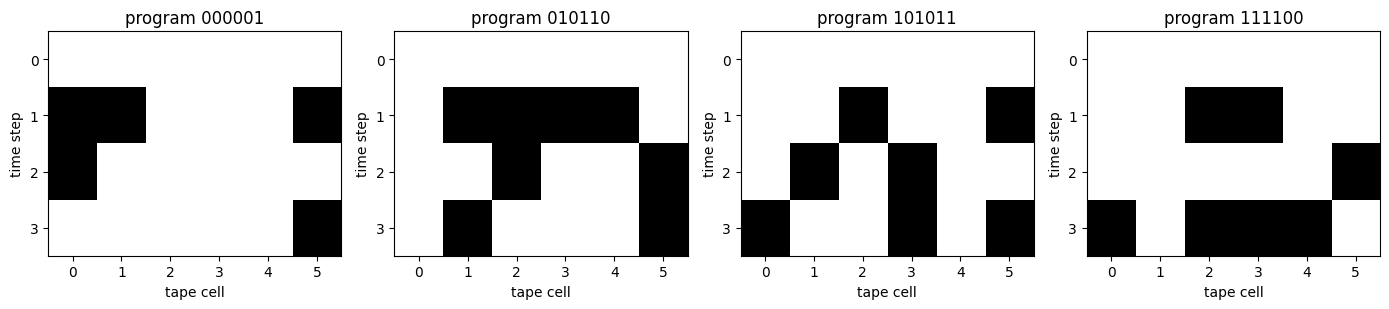

In [4]:
sample_programs = [0b000001, 0b010110, 0b101011, 0b111100]
fig, axes = plt.subplots(1, len(sample_programs), figsize=(14, 3.2))
for ax, pgm in zip(axes, sample_programs):
    ax.imshow(evolve_trace(pgm), cmap='Greys', vmin=0, vmax=1, aspect='auto')
    ax.set_title(f"program {pgm:0{P}b}")
    ax.set_xlabel("tape cell"); ax.set_ylabel("time step")
    ax.set_yticks(range(tcyc + 1))
plt.tight_layout(); plt.show()

## The universal distribution after $t$ steps

Superpose all $N$ programs, evolve $t$ steps, and read the tape: the marginal is the **universal
distribution** $D(s)=M(s)/N$. It matches the classical enumeration exactly (the reversible evolution is
faithfully unitary).

distinct outputs: 32 of 64 | quantum marginal == classical counts: True


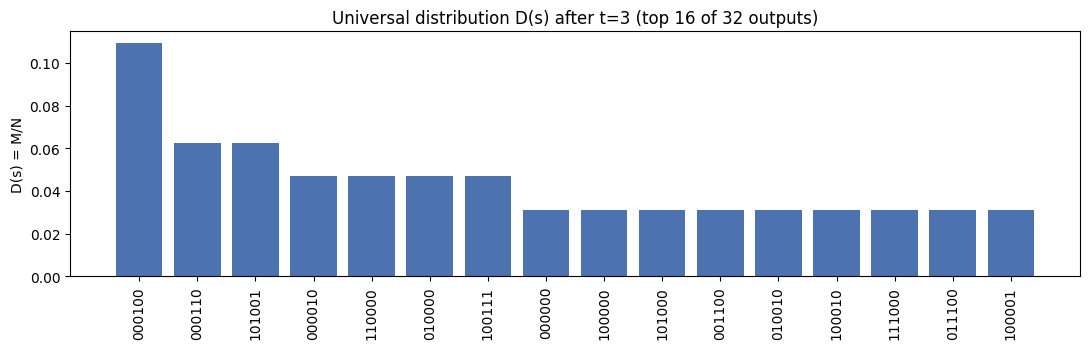

In [5]:
# classical ground-truth counts
counts = {}
for p in range(N):
    s = output_of(p)
    counts[s] = counts.get(s, 0) + 1

# quantum superposition marginal
qc = QuantumCircuit(W); qc.h(prog)
for _ in range(tcyc):
    apply_step_quantum(qc)
ptape = Statevector(qc).probabilities(tape)
qcount = {s: int(round(ptape[s] * N)) for s in range(2 ** T) if ptape[s] > 1e-9}
print("distinct outputs:", len(counts), "of", 2 ** T,
      "| quantum marginal == classical counts:", 
      all(qcount.get(s, 0) == counts.get(s, 0) for s in set(counts) | set(qcount)))

order = sorted(counts, key=lambda s: -counts[s])[:16]
plt.figure(figsize=(11, 3.6))
plt.bar([format(s, f'0{T}b') for s in order], [counts[s] / N for s in order], color='#4C72B0')
plt.title(f"Universal distribution D(s) after t={tcyc} (top 16 of {len(counts)} outputs)")
plt.ylabel("D(s) = M/N"); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

## Application: CTM / algorithmic probability via **QFT-free amplitude estimation**

Estimating $D(s)$ means counting the $M$ reversible programs whose tape equals a target $s$. We build a
Grover operator $Q$ whose good subspace is `tape == s` (one flag qubit), for which
$$P(\text{good after } Q^{m}) = \sin^2\!\big((2m+1)\theta\big), \qquad \sin^2\theta = M/N,$$
and estimate $\theta$ with **maximum-likelihood amplitude estimation** — a QFT-free member of the iQAE
family: **no counting register**, just a schedule of Grover powers measured on the flag. Then
$M=N\sin^2\theta$, $D=M/N$, $\mathrm{CTM}(s)=-\log_2 D$.

In [6]:
flag = W
WF = W + 1


def comparator(qc, s):
    for i in range(T):
        if not (s >> i) & 1: qc.x(tape[i])
    qc.mcx(tape, flag)
    for i in range(T):
        if not (s >> i) & 1: qc.x(tape[i])


def A_prep(qc, s):
    qc.h(prog)
    for _ in range(tcyc):
        apply_step_quantum(qc)
    comparator(qc, s)


def grover_Q(qc, s):
    qc.z(flag)                                   # S_good: phase-flip good (flag == 1)
    a = QuantumCircuit(WF); A_prep(a, s)
    qc.compose(a.inverse(), inplace=True)
    qc.x(range(WF)); qc.h(WF - 1); qc.mcx(list(range(WF - 1)), WF - 1); qc.h(WF - 1); qc.x(range(WF))
    qc.compose(a, inplace=True)
    qc.global_phase += pi                        # standard Grover operator -> sin^2 law


@lru_cache(maxsize=None)
def prob_good(s, m):
    qc = QuantumCircuit(WF)
    A_prep(qc, s)
    for _ in range(m):
        grover_Q(qc, s)
    return float(Statevector(qc).probabilities([flag])[1])


# pick a target with a moderate count and check the amplitude-estimation law
TARGET = sorted(counts, key=lambda s: abs(counts[s] - 4))[0]
M_true = counts[TARGET]
theta = np.arcsin(np.sqrt(M_true / N))
print(f"target s = {TARGET:0{T}b}   true M = {M_true}   a = M/N = {M_true/N:.4f}\n")
print(f"{'m':>2} {'P(good)':>8} {'sin^2((2m+1)θ)':>15}")
for m in range(6):
    print(f"{m:>2} {prob_good(TARGET, m):>8.4f} {sin((2*m+1)*theta)**2:>15.4f}")

target s = 000110   true M = 4   a = M/N = 0.0625

 m  P(good)  sin^2((2m+1)θ)
 0   0.0625          0.0625


 1   0.4727          0.4727


 2   0.9084          0.9084


 3   0.9613          0.9613


 4   0.5817          0.5817


 5   0.1255          0.1255


In [7]:
def mlae(s, powers, shots, rng):
    # QFT-free maximum-likelihood amplitude estimation over a schedule of Grover powers
    data = [(m, rng.binomial(shots, prob_good(s, m))) for m in powers]
    grid = np.linspace(1e-6, pi / 2 - 1e-6, 3000)
    ll = np.zeros_like(grid)
    for m, hits in data:
        pk = np.sin((2 * m + 1) * grid) ** 2
        ll += hits * np.log(pk + 1e-12) + (shots - hits) * np.log(1 - pk + 1e-12)
    th = grid[np.argmax(ll)]
    queries = shots * sum(2 * m + 1 for m in powers)     # total oracle calls
    return N * np.sin(th) ** 2, queries


rng = np.random.default_rng(0)
M_est, Q = mlae(TARGET, [0, 1, 2, 4, 8], shots=256, rng=rng)
D_est = max(M_est, 1e-9) / N
print(f"MLAE estimate:  M = {M_est:.3f} (true {M_true})   D = {D_est:.4f} (true {M_true/N:.4f})")
print(f"                CTM = {-log2(D_est):.3f} bits (true {-log2(M_true/N):.3f})   using ~{Q} oracle calls")

MLAE estimate:  M = 3.977 (true 4)   D = 0.0621 (true 0.0625)
                CTM = 4.008 bits (true 4.000)   using ~8960 oracle calls


## The quantum advantage and the CTM spectrum

- **(a)** the amplitude-estimation law $P(\text{good})=\sin^2((2m+1)\theta)$ — the peak of information
  used by MLAE.
- **(b)** estimation error vs. oracle queries: QFT-free amplitude estimation $\sim 1/Q$ beats classical
  Monte-Carlo $\sim 1/\sqrt Q$ (the quadratic speedup), with **no counting register**.
- **(c)** the reconstructed CTM spectrum $\mathrm{CTM}(s)=-\log_2 D(s)$ vs. the classical ground truth.

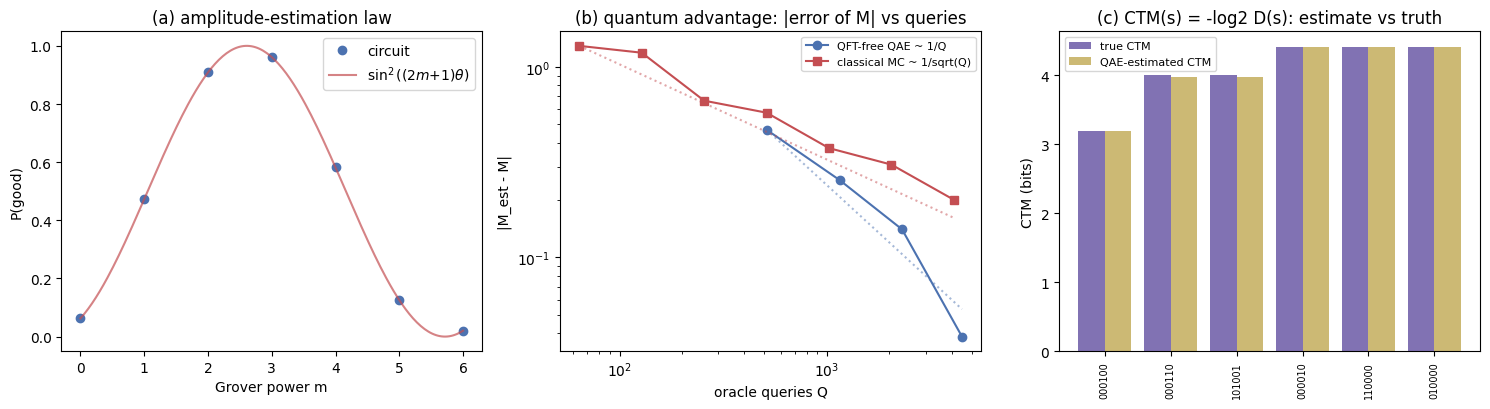

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) amplitude-estimation law
ms = list(range(7))
ax[0].plot(ms, [prob_good(TARGET, m) for m in ms], 'o', color='#4C72B0', label='circuit')
xx = np.linspace(0, 6, 200)
ax[0].plot(xx, np.sin((2 * xx + 1) * theta) ** 2, '-', color='#C44E52', alpha=0.7, label=r'$\sin^2((2m{+}1)\theta)$')
ax[0].set_title('(a) amplitude-estimation law'); ax[0].set_xlabel('Grover power m')
ax[0].set_ylabel('P(good)'); ax[0].legend()

# (b) advantage: error vs oracle queries
schedules = [[0, 1], [0, 1, 2], [0, 1, 2, 4], [0, 1, 2, 4, 8]]
q_Q, q_err = [], []
for sch in schedules:
    trials = [mlae(TARGET, sch, shots=128, rng=np.random.default_rng(r)) for r in range(6)]
    q_Q.append(trials[0][1])
    q_err.append(np.mean([abs(M - M_true) for M, _ in trials]))

def mc_error(s, Q, trials=200):
    e = np.empty(trials)
    for j in range(trials):
        samp = rng.integers(N, size=Q)
        e[j] = abs(N * np.mean([output_of(int(p)) == s for p in samp]) - counts[s])
    return e.mean()

c_Q = [64, 128, 256, 512, 1024, 2048, 4096]
c_err = [mc_error(TARGET, Q) for Q in c_Q]

ax[1].loglog(q_Q, np.maximum(q_err, 1e-3), 'o-', color='#4C72B0', label='QFT-free QAE ~ 1/Q')
ax[1].loglog(c_Q, c_err, 's-', color='#C44E52', label='classical MC ~ 1/sqrt(Q)')
ax[1].loglog(np.array(q_Q, float), q_err[0] * q_Q[0] / np.array(q_Q, float), ':', color='#4C72B0', alpha=0.5)
ax[1].loglog(np.array(c_Q, float), c_err[0] * np.sqrt(c_Q[0]) / np.sqrt(np.array(c_Q, float)), ':', color='#C44E52', alpha=0.5)
ax[1].set_title('(b) quantum advantage: |error of M| vs queries')
ax[1].set_xlabel('oracle queries Q'); ax[1].set_ylabel('|M_est - M|'); ax[1].legend(fontsize=8)

# (c) CTM spectrum estimate vs truth
targets = sorted(counts, key=lambda s: -counts[s])[:6]
ctm_true = [-log2(counts[s] / N) for s in targets]
ctm_est = []
for s in targets:
    M_e, _ = mlae(s, [0, 1, 2, 4, 8], shots=256, rng=np.random.default_rng(5))
    ctm_est.append(-log2(max(M_e, 1e-9) / N))
x = np.arange(len(targets)); w = 0.4
ax[2].bar(x - w / 2, ctm_true, w, label='true CTM', color='#8172B3')
ax[2].bar(x + w / 2, ctm_est, w, label='QAE-estimated CTM', color='#CCB974')
ax[2].set_xticks(x); ax[2].set_xticklabels([format(s, f'0{T}b') for s in targets], rotation=90, fontsize=7)
ax[2].set_title('(c) CTM(s) = -log2 D(s): estimate vs truth')
ax[2].set_ylabel('CTM (bits)'); ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

## Takeaways

- **Reversible programs remove the reset/history qubits.** Each superposed program is a unitary
  permutation, so $U_{\text{step}}^{t}$ is exactly invertible (fidelity 1) and iterates in place — the
  qubit budget is just `program + tape + state` (+1 flag for counting), with none of the per-tick
  history that forces 2-2-1 above 54 qubits.
- **Genuine reversible dynamics + a real universal distribution.** The space-time diagrams show
  distinct reversible rules, and the superposed evolution reproduces the classical output-frequency
  distribution $D(s)$ exactly.
- **CTM via QFT-free amplitude estimation.** Counting the programs that output $s$ with a Grover
  operator + maximum-likelihood (iQAE-family) estimation needs **no counting register** and shows the
  $1/Q$ vs $1/\sqrt Q$ **quadratic speedup**, recovering $D(s)$ and $\mathrm{CTM}(s)$ to the classical
  ground truth.

**Scaling on a simulator.** The Grover reflection's full-width `mcx` is the cost driver; to go larger,
swap `Statevector` for `AerSimulator` (shots, MPS/GPU), replace MLAE with interval-based **IQAE**
(fewer, shallower circuits), and compress the `tape == s` test into a single comparator flag. The
reversible construction is what makes the width grow only linearly in tape/program size.

## Real-world (ML) applications, relevant string sizes, and the resource wall

**Where reversible quantum algorithmic probability / CTM is useful — especially in ML.**

- **Algorithmic-complexity features (BDM/CTM).** Kolmogorov-complexity features for ML on binary
  sequences, images and graphs capture *causal / structural* regularities that Shannon-entropy and
  compression miss (Zenil, Gauvrit, Soler-Toscano) — used in time-series, psychometrics, image and
  network analysis.
- **Solomonoff / MDL inductive priors.** Algorithmic probability is the ideal Occam prior;
  approximations drive minimum-description-length model selection, program synthesis and meta-learning.
- **Algorithmic Information Dynamics (AID) for causal discovery.** Perturbation-based complexity of
  adjacency-matrix blocks exposes causal structure in gene-regulatory and neural networks.
- **Speed-prior RL / AIXI approximations, anomaly / OOD detection** (low algorithmic probability =
  atypical), and **synthetic-biology sequence design** (in-quanto fitness over DNA/protein strings).

**At what string sizes does the quantum version become relevant?** The classical CTM/ACSS table is
built from 5-state 2-symbol Turing machines ($\sim 10^{13}$ machines, $\sim 18$ supercomputer-days) and
**saturates around $L\approx 12$–$13$ binary symbols**. Below that, just use the lookup table. The
quantum extension only matters for $L\gtrsim 13$, and is genuinely new for **$L\approx 16$–$40$** — the
block sizes that bridge BDM's "causal gap" for genomics (gene / protein-interaction blocks) and network
complexity, which is exactly the regime the paper targets.

**The resource wall.** With the *reversible* construction the width is only
$\text{qubits} \approx P + T + S + 1 \approx 2L + 2$ (program + tape + state + flag — the per-tick
**reset/history register is gone**). Circuit depth $\approx K\,(t\cdot T)$ two-qubit gates, statevector
memory $= 16\cdot 2^{\text{width}}$ bytes, and QPU wall $\approx \text{shots}\cdot 2K\cdot(\text{2q per
Grover})\cdot\tau_{2q}$. The next cell makes this concrete (order-of-magnitude, assumptions explicit).

> **Caveat.** Estimating a *maximally-random* string's probability is intrinsically hard
> ($D\sim 2^{-L}\Rightarrow$ Grover depth $K\sim 1/D\sim 2^{L}$); the quantum win is **quadratic over
> classical**, largest for high-probability / modal outputs and for spectrum/counting tasks. The table
> fixes a modest amplitude precision ($K=100$, $\varepsilon\sim 1\%$).

  L qubits 2q/Grover deepest 2q   sim mem        sim QPU/target 2q fid req phys (FT)
  8     18      1816     181600    4.2 MB     laptop    726.4 s    5.5e-07      5184
 12     26      3768     376800    1.1 GB     laptop   25.1 min    2.7e-07      8788
 14     30      5008     500800   17.2 GB     laptop   33.4 min    2.0e-07     10140
 16     34      6424     642400  274.9 GB        HPC   42.8 min    1.6e-07     11492
 20     42      9784     978400   70.4 TB        HPC   65.2 min    1.0e-07     14196
 24     50     13848    1384800   18.0 PB infeasible   92.3 min    7.2e-08     19600
 32     66     24088    2408800 1.2e+03 EB infeasible  160.6 min    4.2e-08     25872
 48     98     53016    5301600 5.1e+12 EB infeasible  353.4 min    1.9e-08     44100
 64    130     93208    9320800 2.2e+22 EB infeasible  621.4 min    1.1e-08     58500


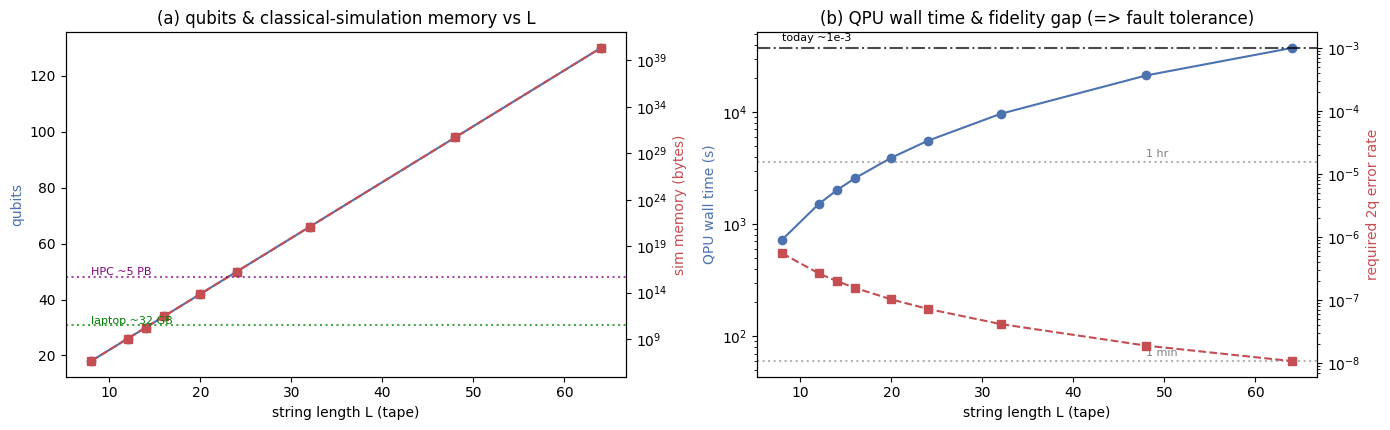

In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# ---- order-of-magnitude resource model (assumptions explicit, easy to change) ----------
n_symbols, m_states = 2, 2          # binary alphabet, 2 internal states (S = 1 qubit)
TOFFOLI_2Q, FREDKIN_2Q = 6, 8       # 2-qubit gates per CCX / CSWAP after decomposition
K_grover = 100                      # Grover iterations at amplitude-estimation precision eps ~ 1/K
shots     = 10_000
tau_2q    = 200e-9                  # superconducting 2-qubit gate time (s)
p2_now    = 1e-3                    # current 2-qubit error rate
p_thresh  = 1e-2                    # surface-code threshold


def htime(s):
    for u, f in [("s", 1), ("min", 60), ("hr", 3600), ("day", 86400)]:
        if s < f * 1000: return f"{s/f:.1f} {u}"
    return f"{s/3.15e7:.1e} yr"

def hbytes(b):
    for u, f in [("KB", 1e3), ("MB", 1e6), ("GB", 1e9), ("TB", 1e12), ("PB", 1e15)]:
        if b < f * 1000: return f"{b/f:.1f} {u}"
    return f"{b/1e18:.1e} EB"


def estimate(L):
    T = P = L; S = 1
    width = P + T + S + 1                              # NO reset/history qubits
    g_step = P + T * TOFFOLI_2Q + (T // 2) * FREDKIN_2Q
    A2q = L * g_step + 12 * T                          # t = L cycles + comparator mcx(tape)
    Q2q = 2 * A2q + 12 * width                         # one Grover operator (+ reflection)
    deepest = K_grover * Q2q
    sim_bytes = (2.0 ** width) * 16
    qpu_wall = shots * (2 * K_grover) * Q2q * tau_2q   # per target string
    p2_req = 0.1 / deepest                             # total error < 0.1 in deepest circuit
    if p2_req >= p2_now:
        phys, d = width, 1
    else:
        d = max(3, int(np.ceil(2 * np.log(p2_req) / np.log(p2_now / p_thresh) - 1)))
        phys = width * 2 * d * d                       # ~ surface-code physical qubits
    sv = "laptop" if sim_bytes <= 32e9 else ("HPC" if sim_bytes <= 5e15 else "infeasible")
    return dict(L=L, qubits=width, Q2q=Q2q, deepest=deepest, sim_bytes=sim_bytes,
                sim=sv, qpu=qpu_wall, p2_req=p2_req, phys=phys)


Ls = [8, 12, 14, 16, 20, 24, 32, 48, 64]
rows = [estimate(L) for L in Ls]

print(f"{'L':>3} {'qubits':>6} {'2q/Grover':>9} {'deepest 2q':>10} {'sim mem':>9} {'sim':>10}"
      f" {'QPU/target':>10} {'2q fid req':>10} {'phys (FT)':>9}")
for r in rows:
    print(f"{r['L']:>3} {r['qubits']:>6} {r['Q2q']:>9} {r['deepest']:>10} {hbytes(r['sim_bytes']):>9}"
          f" {r['sim']:>10} {htime(r['qpu']):>10} {r['p2_req']:>10.1e} {r['phys']:>9}")

# ---- plots -----------------------------------------------------------------------------
L = np.array([r['L'] for r in rows])
qub = np.array([r['qubits'] for r in rows])
mem = np.array([r['sim_bytes'] for r in rows])
qpu = np.array([r['qpu'] for r in rows])
fid = np.array([r['p2_req'] for r in rows])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))

ax[0].plot(L, qub, 'o-', color='#4C72B0', label='qubits (= 2L+2)')
ax[0].set_xlabel('string length L (tape)'); ax[0].set_ylabel('qubits', color='#4C72B0')
ax2 = ax[0].twinx()
ax2.semilogy(L, mem, 's--', color='#C44E52', label='statevector memory')
ax2.axhline(32e9, color='green', ls=':', alpha=.7); ax2.text(8, 4e10, 'laptop ~32 GB', color='green', fontsize=8)
ax2.axhline(5e15, color='purple', ls=':', alpha=.7); ax2.text(8, 7e15, 'HPC ~5 PB', color='purple', fontsize=8)
ax2.set_ylabel('sim memory (bytes)', color='#C44E52')
ax[0].set_title('(a) qubits & classical-simulation memory vs L')

ax[1].semilogy(L, qpu, 'o-', color='#4C72B0', label='QPU wall / target (200 ns 2q, 1e4 shots)')
ax[1].set_xlabel('string length L (tape)'); ax[1].set_ylabel('QPU wall time (s)', color='#4C72B0')
for y, lbl in [(60, '1 min'), (3600, '1 hr')]:
    ax[1].axhline(y, color='grey', ls=':', alpha=.6); ax[1].text(48, y * 1.1, lbl, fontsize=8, color='grey')
ax3 = ax[1].twinx()
ax3.semilogy(L, fid, 's--', color='#C44E52', label='2q fidelity required')
ax3.axhline(p2_now, color='black', ls='-.', alpha=.7); ax3.text(8, p2_now * 1.3, 'today ~1e-3', fontsize=8)
ax3.set_ylabel('required 2q error rate', color='#C44E52')
ax[1].set_title('(b) QPU wall time & fidelity gap (=> fault tolerance)')

plt.tight_layout(); plt.show()

### Reading the numbers

- **Classical simulation** is fine up to $L\approx 14$ (~30 qubits, tens of GB), reaches HPC limits by
  $L\approx 22$–$24$ (~50 qubits, PB-scale), and is **flatly infeasible beyond** — while the
  ML-relevant regime ($L\approx 16$–$40$) already sits *past* exact simulation. That is exactly why a
  quantum accelerator is needed here rather than a bigger classical run.
- **QPU wall time** is modest — minutes per target string at 200 ns two-qubit gates and $10^4$ shots
  (fixed $\varepsilon\!\sim\!1\%$ precision, $K=100$); it grows only polynomially in $L$.
- **The real gate is fidelity.** The deepest circuit has $\sim\!10^{5}$–$10^{6}$ two-qubit gates, so it
  needs a two-qubit error rate of $\sim\!10^{-7}$–$10^{-8}$, whereas today's hardware is $\sim\!10^{-3}$
  — a **4–5 order-of-magnitude gap**. Bridging it means **fault tolerance**: roughly $10^{4}$–$10^{5}$
  physical qubits (surface code) for $L\approx 16$–$32$. So near-term devices can *run the circuits*
  but not yet *trust the answer*; the reversible construction's value is that it keeps the **logical**
  width at $\approx 2L+2$, minimising the fault-tolerant overhead.

## References for the application claims

Each claim in the *applications* section above is grounded in the following (the source framework's
bibliography plus standard AIT/ML and quantum-amplitude-estimation literature).

**Source framework (this notebook's basis)**
1. A. Sarkar, Z. Al-Ars, K. Bertels. *Estimating Algorithmic Information Using Quantum Computing for
   Genomics Applications.* Applied Sciences 11(6), 2696 (2021).
2. A. Sarkar, Z. Al-Ars, K. Bertels. *Quantum Accelerated Estimation of Algorithmic Information.*
   arXiv:2006.00987 (2020) — the detailed QPULBA circuit construction.

**Algorithmic probability, universal distribution, Kolmogorov complexity (the metric being estimated)**
3. R. J. Solomonoff. *A Formal Theory of Inductive Inference, Part I.* Information and Control 7(1),
   1–22 (1964).
4. A. N. Kolmogorov. *Three Approaches to the Quantitative Definition of Information.* Problems of
   Information Transmission 1(1), 1–7 (1965).
5. L. A. Levin. *Laws of information conservation (non-growth) …* (the Coding Theorem), Problems of
   Information Transmission 10(3), 206–210 (1974).
6. M. Li, P. Vitányi. *An Introduction to Kolmogorov Complexity and Its Applications.* Springer,
   4th ed. (2019).

**CTM / BDM and the ACSS table — the L≈12–13 classical limit and the "causal gap"**
7. J.-P. Delahaye, H. Zenil. *Numerical evaluation of algorithmic complexity for short strings.*
   Applied Mathematics and Computation 219(1), 63–77 (2012).
8. F. Soler-Toscano, H. Zenil, J.-P. Delahaye, N. Gauvrit. *Calculating Kolmogorov Complexity from the
   Output Frequency Distributions of Small Turing Machines.* PLoS ONE 9(5): e96223 (2014) — CTM/ACSS,
   the 5-state/2-symbol enumeration and its cost.
9. N. Gauvrit, H. Singmann, F. Soler-Toscano, H. Zenil. *Algorithmic Complexity for Short Binary
   Strings Applied to Psychology: a primer.* Behavior Research Methods 46, 732–744 (2014); the `acss`
   R package.
10. H. Zenil, F. Soler-Toscano, J.-P. Delahaye, N. Gauvrit. *Two-dimensional Kolmogorov complexity and
    an empirical validation of the Coding Theorem Method by compressibility.* PeerJ Comp. Sci. 1:e23
    (2015) — BDM.
11. H. Zenil et al. *A Decomposition Method for Global Evaluation of Shannon Entropy and Local
    Estimations of Algorithmic Complexity.* Entropy 20(8), 605 (2018) — BDM for longer objects.

**ML feature use (sequences, images, graphs, psychometrics, finance)**
— refs 9, 10, 11 above, plus:
12. O. Brandouy, J.-P. Delahaye, L. Ma, H. Zenil. *Algorithmic complexity of financial motions.*
    Research in International Business and Finance 30, 336–347 (2014).

**Solomonoff / MDL inductive priors, program synthesis, meta-learning**
— ref 3 above, plus:
13. J. Rissanen. *Modeling by shortest data description.* Automatica 14(5), 465–471 (1978).
14. P. Grünwald. *The Minimum Description Length Principle.* MIT Press (2007).

**Algorithmic Information Dynamics (AID) — causal discovery in gene-regulatory / neural networks**
15. H. Zenil, N. A. Kiani, F. Marabita, … J. Tegnér. *An Algorithmic Information Calculus for Causal
    Discovery and Reprogramming Systems.* iScience 19, 1160–1172 (2019).
16. H. Zenil, N. A. Kiani, A. A. Zea, J. Tegnér. *Causal deconvolution by algorithmic generative
    models.* Nature Machine Intelligence 1, 58–66 (2019).
17. H. Zenil, N. A. Kiani, J. Tegnér. *Algorithmic Information Dynamics: A Computational Approach to
    Causality with Applications to Living Systems.* Cambridge University Press (2023).

**Genomics (nucleosome occupancy; PPI/BDM extension the paper targets)**
18. H. Zenil, P. Minary. *Training-free measures based on algorithmic probability identify high
    nucleosome occupancy in DNA sequences.* Nucleic Acids Research 47(20): e129 (2019).

**Speed-prior RL / AIXI / quantum universal prediction**
19. J. Schmidhuber. *The Speed Prior: A New Simplicity Measure Yielding Near-Optimal Computable
    Predictions.* COLT 2002, 216–228.
20. M. Hutter. *Universal Artificial Intelligence: Sequential Decisions Based on Algorithmic
    Probability.* Springer (2005).
21. E. Catt, M. Hutter. *A Gentle Introduction to Quantum Computing Algorithms with Applications to
    Universal Prediction.* arXiv:2005.03137 (2020) — motivates quantum counting for the speed prior.

**Synthetic-biology sequence design (in-quanto fitness)**
22. C. Angermueller et al. *Population-Based Black-Box Optimization for Biological Sequence Design.*
    arXiv:2006.03227 (2020).

**Quantum counting / amplitude estimation (the counting subroutine; QFT-free / iQAE used here)**
23. G. Brassard, P. Høyer, A. Tapp. *Quantum Counting.* ICALP 1998, LNCS 1443, 820–831.
24. Y. Suzuki, S. Uno, R. Raymond, T. Tanaka, T. Onodera, N. Yamamoto. *Amplitude estimation without
    phase estimation.* Quantum Information Processing 19, 75 (2020) — maximum-likelihood AE (used in
    this notebook).
25. D. Grinko, J. Gacon, C. Zoufal, S. Woerner. *Iterative quantum amplitude estimation.* npj Quantum
    Information 7, 52 (2021) — IQAE (the drop-in for larger runs).
26. S. Aaronson, P. Rall. *Quantum Approximate Counting, Simplified.* SOSA 2020, 24–32.

**Resource / hardware assumptions in the feasibility table**
27. F. Arute et al. *Quantum supremacy using a programmable superconducting processor.* Nature 574,
    505–510 (2019) — representative superconducting two-qubit gate times (tens of ns) and error rates
    (~10⁻³).
28. A. G. Fowler, M. Mariantoni, J. M. Martinis, A. N. Cleland. *Surface codes: Towards practical
    large-scale quantum computation.* Physical Review A 86, 032324 (2012) — fault-tolerant
    physical-qubit overhead used for the FT estimates.

*Note:* the "low algorithmic probability ⇒ atypical/anomalous" framing for anomaly/OOD detection
follows directly from the universal-distribution foundations (refs 3, 6) rather than a single dedicated
paper; refs 8, 15–17 provide the empirical algorithmic-complexity machinery it would build on.

## Model-class validity: is a quantum-accelerated **reversible ACSS (Rev-ACSS)** a legitimate BDM proxy?

**Setup.** The counting cell above estimates, over the ensemble $\mathcal{R}_L$ of reversible programs on
a length-$L$ tape,
$$D_{\text{rev}}(s)=\frac{\bigl|\{r\in\mathcal{R}_L : r^{(t)}(0^{L})=s\}\bigr|}{|\mathcal{R}_L|},
\qquad \mathrm{CTM}_{\text{rev}}(s)=-\log_2 D_{\text{rev}}(s),$$
and a block-decomposition $\mathrm{BDM}_{\text{rev}}(x)=\sum_i \mathrm{CTM}_{\text{rev}}(s_i)+\log_2 n_i$
(block multiplicities $n_i$). Can $\mathrm{CTM}_{\text{rev}}$ stand in for the standard-TM $\mathrm{CTM}$
(the ACSS table) as a proxy for the uncomputable $K$?

**Why it is well-defined and asymptotically equivalent.**
- *Reversible universality* (Bennett 1973): the primitives used here (`CCX`/`CSWAP` + ancilla) are
  Toffoli-universal, so $\mathcal{R}_L$ is a computationally universal reference machine and
  $K_{\text{rev}}$ exists.
- *Invariance theorem* (Solomonoff; Kolmogorov; Li & Vitányi): $|K_{\text{rev}}(s)-K(s)|\le c$ with $c$
  independent of $s$ — the "compiler length" between the two reference machines.
- *Coding theorem* (Levin): $-\log_2 D(s)=K(s)+O(1)$ for a reference machine obeying it; empirically the
  induced ranking is robust across model classes — even resource-bounded / sub-universal machines
  reproduce coding-theorem-like behaviour and rank-correlate with the universal distribution
  (Zenil, Badillo, Hernández-Orozco, Hernández-Quiroz 2019).

So **asymptotically $\mathrm{CTM}_{\text{rev}}$ is the same measure**, and the *ranking* that gives BDM
its edge over entropy is expected to transfer.

**Where it differs — the reversibility bias (formal).** CTM/BDM act on *short* blocks, exactly where the
$O(1)$ constant is not negligible. Two structural effects:
1. *Bennett garbage / Landauer penalty.* A reversible machine emulating an irreversible (many-to-one,
   erasing) generator must retain history, so its shortest program is longer; hence
   $\mathrm{CTM}_{\text{rev}}$ **over-estimates** the complexity of contractive / lossy outputs (erasure
   sinks, fixed-point attractors) relative to standard ACSS (Landauer 1961; Bennett 1973).
2. *Bijectivity.* Each step is a permutation, so the heavy modes of $D(s)$ (in classical ACSS dominated
   by erasure-reachable strings such as the all-zeros sink) are reshaped. The tail / rank is largely
   preserved; the head is model-dependent.

**Making it a rigorous proxy — the calibration bridge.** Treat $\mathrm{CTM}_{\text{rev}}$ as a
*sibling estimator* (like 2-D CTM or compression-BDM) and anchor it on the overlap $L\le 12$ where
classical ACSS exists:
$$\mathrm{CTM}_{\text{std}}(s)\;\approx\;\alpha\,\mathrm{CTM}_{\text{rev}}(s)+\beta,\qquad
\rho_{\text{Spearman}}\big(\mathrm{CTM}_{\text{rev}},\mathrm{CTM}_{\text{std}}\big)\gtrsim 0.8\ \text{(expected)}.$$
Fit $(\alpha,\beta)$ and the residual on $L\le 12$, then extrapolate to $L\sim 16$ (past classical reach)
carrying the residual as an error bar. A high $\rho$ both *justifies* the proxy and *supplies* the
correction.

**Covering irreversible generators when needed.** Add a **garbage ancilla the program may write into**
(Bennett embedding): $\mathcal{R}_L$ then represents irreversible transforms too, at the cost of extra
qubits — i.e. the reset/history register we removed returns as a *tunable knob* (pure-reversible ↔
reversible-with-garbage), selectable by the calibration fit.

**Causal gap vs. model bias — keep them separate.**
- *Block-size gap* (BDM blind beyond block length): the quantum-reversible extension **shrinks** it by
  pushing $L$ from ~13 toward ~16+.
- *Model-class bias* (reversible vs. irreversible): an **orthogonal** axis, handled by calibration or the
  garbage knob.

**When Rev-ACSS is the *better* proxy.** For plausibly reversible / physical generators —
Hamiltonian / unitary dynamics, conservative or reversible cellular automata, quantum processes,
error-correcting codes — the reversible reference machine is *more* faithful than the irreversible-TM
ACSS; it is only a liability for dissipative / selective generators, where the garbage knob and
calibration recover it.

*A concrete validation (simulable today):* build Rev-ACSS for $L\le 12$, compute Spearman $\rho$ and the
affine offset $(\alpha,\beta)$ against classical ACSS; that both tests coding-theorem behaviour and
yields the extrapolation map to $L\sim 16$.

*Additional references (extending the list above):*
29. C. H. Bennett. *Logical reversibility of computation.* IBM J. Res. Dev. 17(6), 525–532 (1973).
30. R. Landauer. *Irreversibility and heat generation in the computing process.* IBM J. Res. Dev. 5(3),
    183–191 (1961).
31. H. Zenil, L. Badillo, S. Hernández-Orozco, F. Hernández-Quiroz. *Coding-theorem-like behaviour and
    emergence of the universal distribution from resource-bounded algorithmic probability.* Int. J.
    Parallel, Emergent and Distributed Systems 34(2), 161–180 (2019).

## Using quantum-accelerated BDM in a science / decision pipeline (synth-bio & AIXI)

**Architecture — the QPU is an offline cache-filler, not a per-decision dependency.** Because
$\mathrm{BDM}(x)=\sum_i \mathrm{CTM}(s_i)+\log_2 n_i$ factorizes:
- *Offline (quantum):* extend the **Rev-ACSS lookup table** with quantum-accelerated counting (the one
  expensive, fault-tolerance-limited step). Store it as a plain classical table.
- *Online (classical, cheap):* BDM = table lookups + a log term — runs per decision, at scale, on any
  device.
- *Cache semantics:* inference is mostly table **hits**; a **miss** (a novel block) triggers a
  **batched** quantum job. The QPU is a periodic batch resource, keeping the fault-tolerant cost
  (previous section) off the decision loop.

**Synthetic-biology pipeline.**
- *Sequence design (generative loop):* candidate DNA / protein sequences → block-decompose into k-mers →
  $\mathrm{BDM}_{\text{rev}}$ score used as a **fitness / regularizer** in a GA / Bayesian-optimization /
  GAN loop (Angermueller et al. 2020), targeting a desired algorithmic-complexity profile rather than
  GC-content / entropy. The quantum extension lets the block size match **biological interaction ranges**
  (motifs ~16–20 bp) instead of the classical cap at ~12.
- *Causal / regulatory inference (AID):* encode a gene-regulatory or protein-interaction network as an
  adjacency matrix; rank interventions by the drop in $\mathrm{BDM}$ under perturbation → predict driver
  genes / reprogramming targets (Zenil et al., *Algorithmic Information Dynamics*, 2019 / 2023).
- *Decision layer:* $\mathrm{BDM}$ as the algorithmic **prior / acquisition** term in Bayesian
  design-of-experiments → choose the next wet-lab assay (active learning) → update. Since biology is
  dissipative, use the **garbage-ancilla** variant or **relative** BDM, and propagate the calibration
  error bars into the acquisition function.

**AIXI / RL pipeline.** The runtime-bounded QPULBA is essentially a **speed prior** (Schmidhuber 2002;
Catt & Hutter 2020) — a *computable*, quantum-accelerable stand-in for the Solomonoff prior in AIXI
(Hutter 2005).
- *Prior estimation:* the quantum universal distribution $D(s)$ is the approximate speed / Solomonoff
  prior over short program / observation strings; BDM extends it to long histories by block
  decomposition.
- *Model scoring:* rank world-models by the $\mathrm{BDM}$ residual of predicted-vs-observed sequence
  (low residual = good algorithmic compression = high posterior).
- *Decision layer:* feed the algorithmic-probability-weighted model mixture into planning / value
  estimation; select actions by expected reward. Novel high-probability substrings absent from the table
  trigger **active cache growth** (batched quantum jobs).

**Cross-cutting rules.**
- *Calibrate → error-bar → decide:* carry the Rev-ACSS → ACSS calibration residual as uncertainty into
  the acquisition / planning layer.
- *Match the model class to the substrate:* reversible for physical / quantum generators;
  garbage-ancilla or relative-BDM for dissipative / biological ones.
- *Spend the QPU only where entropy fails:* route quantum-BDM to causal-inference / anomaly / design
  tasks with low statistical signature (algorithmic structure that gzip / entropy miss); use compression
  where it already suffices.

*References for this section:* 1–2 (framework), 8 & 11 (CTM/BDM), 15–18 (AID, genomics), 19–21 (speed
prior, AIXI), 22 (sequence design).